# EDA — Data4Cyber S6 (compromiso del canal de precio MQTT)

Continuación del EDA de `EDA_data4cyber.ipynb`. Mismo esqueleto (estructura, nulos, distribuciones, correlación, ACP) y las mismas funciones auxiliares, pero aplicado al escenario **S6** y con cuatro bloques nuevos: estructura temporal, auditoría de fuga, costo del promedio y una sonda cronológica.

**Por qué S6 primero**

- Es el único escenario donde la variable manipulada (el precio MQTT) es una feature directa, no un efecto diluido entre cinco medidores.
- El ataque ocupa el 75 % de las filas: sirve para discutir desbalanceo desde el arranque.
- Tiene una trampa específica: el canal MQTT solo se registra durante la ventana de ataque. Si no se audita, cualquier modelo "aprende" eso y reporta una performance falsa.

**Qué se agrega respecto del EDA S1**

1. Estructura temporal: el escenario son bloques contiguos, no filas intercambiables.
2. Auditoría de fuga: `attack_phase`, `MQTT-Price-Signal.event` y la ausencia del precio.
3. Efecto sobre el medidor atacado y cuánto se pierde al promediar los cinco medidores.
4. Sonda cronológica: qué se puede afirmar con un split honesto y qué no.

## 0. Configuración y carga

Se lee `datasetS6.csv` desde Drive en Colab o desde `datasets/` si se ejecuta en el repo. No se imputa nada acá: la imputación es parte del pipeline de modelado y se ajusta **solo con train**.

In [ ]:
%matplotlib inline

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 110

SCENARIO = "S6"

try:
    from google.colab import drive
    drive.mount("/content/gdrive/")
    BASE = "/content/gdrive/MyDrive/TrabajoFinal/datasets/"
except ImportError:
    BASE = "datasets/"

candidatos = [
    os.path.join(BASE, f"dataset{SCENARIO}.csv"),
    os.path.join("datasets", f"dataset{SCENARIO}.csv"),
    os.path.join("..", "datasets", f"dataset{SCENARIO}.csv"),
]
path = next((p for p in candidatos if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(f"no encontré dataset{SCENARIO}.csv en: {candidatos}")

df = pd.read_csv(path)
df["timestamp"] = pd.to_datetime(df["timestamp"])

print("archivo:", path)
print(f"filas: {len(df):,} | columnas: {df.shape[1]}")
df.head()

archivo: ../datasets/datasetS6.csv
filas: 1,800 | columnas: 156


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-06 13:48:00.690+00:00,False,normal,normal,0.673807,0.669863,0.761964,49.996468,0.091451,0.405029,0.386499,0.423296,44.741913,1,17.316277,14.831735,12.593901,44.557533,18.457256,15.855508,10.244770,17.180131,288.882965,96.440773,91.743080,100.699112,411.613831,411.530640,412.449585,238.108246,...,NaN,NaN,-0.897138,-0.897510,-0.898345,49.995262,0.845426,17.987444,17.896862,17.966761,-11148.832031,1,-3720.048584,-3697.885986,-3730.897217,5494.071289,1838.845947,1823.888794,1831.336182,8.864024e+08,12634.075195,4222.404785,4191.768555,4219.901367,406.085846,406.214203,406.780334,234.741791,234.218079,234.872696
1,2026-03-06 13:48:01.690+00:00,False,normal,normal,0.673807,0.669863,0.761964,49.996468,0.091451,0.405029,0.386499,0.423296,44.741913,1,17.316277,14.831735,12.593901,44.557533,18.457256,15.855508,10.244770,17.180131,288.882965,96.440773,91.743080,100.699112,411.613831,411.530640,412.449585,238.108246,...,NaN,NaN,-0.897138,-0.897510,-0.898345,49.995262,0.845426,17.987444,17.896862,17.966761,-11148.832031,1,-3720.048584,-3697.885986,-3730.897217,5494.071289,1838.845947,1823.888794,1831.336182,8.864024e+08,12634.075195,4222.404785,4191.768555,4219.901367,406.085846,406.214203,406.780334,234.741791,234.218079,234.872696
2,2026-03-06 13:48:02.690+00:00,False,normal,normal,0.673807,0.669863,0.761964,49.996468,0.091451,0.405029,0.386499,0.423296,44.741913,1,17.316277,14.831735,12.593901,44.557533,18.457256,15.855508,10.244770,17.180131,288.882965,96.440773,91.743080,100.699112,411.613831,411.530640,412.449585,238.108246,...,NaN,NaN,-0.897138,-0.897510,-0.898345,49.995262,0.845426,17.987444,17.896862,17.966761,-11148.832031,1,-3720.048584,-3697.885986,-3730.897217,5494.071289,1838.845947,1823.888794,1831.336182,8.864024e+08,12634.075195,4222.404785,4191.768555,4219.901367,406.085846,406.214203,406.780334,234.741791,234.218079,234.872696
3,2026-03-06 13:48:03.690+00:00,False,normal,normal,0.673807,0.669863,0.761964,49.996468,0.091451,0.405029,0.386499,0.423296,44.741913,1,17.316277,14.831735,12.593901,44.557533,18.457256,15.855508,10.244770,17.180131,288.882965,96.440773,91.743080,100.699112,411.613831,411.530640,412.449585,238.108246,...,NaN,NaN,-0.897138,-0.897510,-0.898345,49.995262,0.845426,17.987444,17.896862,17.966761,-11148.832031,1,-3720.048584,-3697.885986,-3730.897217,5494.071289,1838.845947,1823.888794,1831.336182,8.864024e+08,12634.075195,4222.404785,4191.768555,4219.90136

## 0.1 Guía de lectura

Antes de mirar números, fijemos qué es qué en este escenario:

- `attack_active` es la **etiqueta**, no una feature. Nunca entra en `X`.
- `attack_phase` y `attack_phase_all` son etiquetas derivadas de la misma anotación: si entran, predicen el 100 %.
- `MQTT-Price-Signal.price_eur_per_kwh` es el canal atacado. Su valor es señal; su **ausencia** es artefacto de registro.
- `Profile.*` describe contexto operativo (irradiancia, cargas, temperatura): son features legítimas.
- Los medidores Janitza registran el efecto físico del ataque. Ahí está la señal que va a generalizar.

## 1. Estructura del escenario

Lo primero es lo mismo que en S1: cuántas filas, si el tiempo está duplicado o tiene huecos, y cómo se reparten las columnas. La diferencia es que acá el orden temporal importa mucho más.

In [ ]:
print(f"filas: {len(df):,} | columnas: {df.shape[1]}")
print("\ntipos de dato:")
print(df.dtypes.astype(str).value_counts().to_string())
print(f"\nduplicados exactos: {int(df.duplicated().sum())}")
print(f"duplicados de timestamp: {int(df['timestamp'].duplicated().sum())}")
print("columnas no numéricas:", [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])])

filas: 1,800 | columnas: 156

tipos de dato:
float64                145
int64                    5
str                      4
datetime64[us, UTC]      1
bool                     1

duplicados exactos: 0
duplicados de timestamp: 0
columnas no numéricas: ['timestamp', 'attack_phase', 'attack_phase_all', 'MQTT-Price-Signal.event', 'Profile.timestamp']


In [ ]:
t = df["timestamp"].sort_values()
dt = t.diff().dt.total_seconds().dropna()

print(f"desde {t.min()} hasta {t.max()}")
print(f"duración: {t.max() - t.min()}")
print("\nseparación entre filas consecutivas (top 5):")
print(dt.value_counts().head(5).to_string())
print(f"\nhuecos > 1 s: {int((dt > 1).sum())} | filas fuera de la grilla de 1 s: {int((dt != 1).sum())}")

desde 2026-03-06 13:48:00.690000+00:00 hasta 2026-03-06 14:17:59.690000+00:00
duración: 0 days 00:29:59

separación entre filas consecutivas (top 5):
timestamp
1.0    1799

huecos > 1 s: 0 | filas fuera de la grilla de 1 s: 0


In [ ]:
resumen = pd.DataFrame({
    "filas": [len(df)],
    "ataques": [int(df.attack_active.sum())],
    "benignas": [int((~df.attack_active).sum())],
    "tasa de ataque": [round(float(df.attack_active.mean()), 3)],
})
display(resumen)
print("ataque por fase:")
display(pd.crosstab(df.attack_phase, df.attack_active, margins=True))
print("valores de attack_phase_all:")
display(df.attack_phase_all.value_counts(dropna=False).to_frame("filas"))

,filas,ataques,benignas,tasa de ataque
0,1800,1350,450,0.75


ataque por fase:


attack_active,False,True,All
attack_phase,,,
normal,450,0,450
s6_attack_mqtt,0,900,900
s6_mqtt_price_manipulation,0,450,450
All,450,1350,1800


valores de attack_phase_all:


,filas
attack_phase_all,
s6_attack_mqtt,900
normal,450
s6_attack_mqtt;s6_mqtt_price_manipulation,450


In [ ]:
seg = (df.attack_active != df.attack_active.shift()).cumsum()
bloques = (df.assign(seg=seg)
             .groupby("seg")
             .agg(inicio=("timestamp", "min"),
                  fin=("timestamp", "max"),
                  segundos=("timestamp", "size"),
                  ataque=("attack_active", "first"),
                  fase=("attack_phase", "first"),
                  evento=("MQTT-Price-Signal.event",
                          lambda s: s.dropna().iloc[0][:45] if s.notna().any() else "(vacío)"))
             .reset_index(drop=True))
bloques["duracion_s"] = (bloques["fin"] - bloques["inicio"]).dt.total_seconds().add(1).astype(int)

display(bloques[["inicio", "fin", "segundos", "duracion_s", "ataque", "fase", "evento"]])
print(f"{len(bloques)} bloques contiguos: " +
      ", ".join(f"{int(r.segundos)} s {'ataque' if r.ataque else 'benigno'}" for r in bloques.itertuples()))
print("Consecuencia: las filas NO son intercambiables. Un split aleatorio mezcla segundos vecinos de ataque")
print("y de operación normal, y las métricas salen infladas.")

,inicio,fin,segundos,duracion_s,ataque,fase,evento
0,2026-03-06 13:48:00.690+00:00,2026-03-06 13:55:17.690+00:00,438,438,False,normal,(vacío)
1,2026-03-06 13:55:18.690+00:00,2026-03-06 14:17:47.690+00:00,1350,1350,True,s6_attack_mqtt,Simulated compromise started
2,2026-03-06 14:17:48.690+00:00,2026-03-06 14:17:59.690+00:00,12,12,False,normal,Starting 450s recovery period


3 bloques contiguos: 438 s benigno, 1350 s ataque, 12 s benigno
Consecuencia: las filas NO son intercambiables. Un split aleatorio mezcla segundos vecinos de ataque
y de operación normal, y las métricas salen infladas.


## 2. Grupos de columnas

Se reutiliza el diccionario del EDA anterior, con una entrada nueva para la columna `event` que solo existe en S6.

In [ ]:
SIG_TIPO = {
    "uln1": "Tensión fase-neutro", "uln2": "Tensión fase-neutro", "uln3": "Tensión fase-neutro",
    "ull12": "Tensión fase-fase", "ull23": "Tensión fase-fase", "ull31": "Tensión fase-fase",
    "iln1": "Corriente de fase", "iln2": "Corriente de fase", "iln3": "Corriente de fase",
    "i_sum3": "Corriente de neutro",
    "pln1": "Potencia activa", "pln2": "Potencia activa", "pln3": "Potencia activa", "p_sum3": "Potencia activa",
    "sln1": "Potencia aparente", "sln2": "Potencia aparente", "sln3": "Potencia aparente", "s_sum3": "Potencia aparente",
    "qln1": "Potencia reactiva", "qln2": "Potencia reactiva", "qln3": "Potencia reactiva", "q_sum3": "Potencia reactiva",
    "cos_phi1": "Factor de potencia", "cos_phi2": "Factor de potencia", "cos_phi3": "Factor de potencia",
    "freq": "Frecuencia",
    "phase_seq": "Secuencia de fases",
    "realtime": "Marca de tiempo del equipo",
    "event": "Etiqueta de evento",
}
UNIDAD = {
    "Tensión fase-neutro": "V", "Tensión fase-fase": "V", "Corriente de fase": "A",
    "Corriente de neutro": "A", "Potencia activa": "W", "Potencia aparente": "VA",
    "Potencia reactiva": "var", "Factor de potencia": "—", "Frecuencia": "Hz",
    "Secuencia de fases": "—", "Marca de tiempo del equipo": "s",
    "SOC": "fracción 0-1", "Señal de precio": "EUR/kWh", "Contexto de escenario": "—",
    "Etiqueta de evento": "—", "Control / etiquetas": "—", "Desconocido": "?",
}
FASE = {"ull12": "L1-L2", "ull23": "L2-L3", "ull31": "L3-L1"}

def partir(c):
    if "." in c:
        dev, sig = c.split(".", 1)
    else:
        dev, sig = "(sin prefijo)", c
    return dev, sig

def tipo_de(dev, sig):
    if dev == "(sin prefijo)":
        return "Control / etiquetas"
    if dev.startswith("Battery-SOC"):
        return "SOC"
    if dev == "MQTT-Price-Signal":
        return "Señal de precio" if sig != "event" else "Etiqueta de evento"
    if dev == "Profile":
        return "Contexto de escenario"
    return SIG_TIPO.get(sig, "Desconocido")

def fase_de(sig):
    if sig in FASE:
        return FASE[sig]
    if sig.endswith("sum3"):
        return "trifásica"
    if sig.endswith("1"):
        return "L1"
    if sig.endswith("2"):
        return "L2"
    if sig.endswith("3"):
        return "L3"
    return "—"

reg = []
for c in df.columns:
    dev, sig = partir(c)
    t = tipo_de(dev, sig)
    reg.append({"columna": c, "dispositivo": dev, "señal": sig,
                "tipo": t, "unidad": UNIDAD.get(t, "?"), "fase": fase_de(sig)})
cols = pd.DataFrame(reg)

print(f"columnas: {len(cols)} | dispositivos: {cols.dispositivo.nunique()}")
display(cols.groupby(["dispositivo", "tipo"]).size().rename("columnas").reset_index())
display(cols.tipo.value_counts().to_frame("columnas"))

columnas: 156 | dispositivos: 10


,dispositivo,tipo,columnas
0,(sin prefijo),Control / etiquetas,4
1,BSS-Inverter-AC-Meter,Corriente de fase,3
2,BSS-Inverter-AC-Meter,Corriente de neutro,1
3,BSS-Inverter-AC-Meter,Factor de potencia,3
4,BSS-Inverter-AC-Meter,Frecuencia,1
...,...,...,...
56,Substation-AC-Meter,Potencia aparente,4
57,Substation-AC-Meter,Potencia reactiva,4
58,Substation-AC-Meter,Secuencia de fases,1
59,Substation-AC-Meter,Tensión fase-fase,3


,columnas
tipo,
Potencia activa,20
Potencia reactiva,20
Potencia aparente,20
Factor de potencia,15
Corriente de fase,15
Tensión fase-fase,15
Tensión fase-neutro,15
Contexto de escenario,8
Frecuencia,5


## 3. Datos nulos

S6 tiene pocos vacíos en total (0,38 %), pero están **concentrados de forma no aleatoria**: casi todos caen en filas benignas. Eso es información, no ruido, y hay que tratarlo antes de imputar.

In [ ]:
num = df.select_dtypes(include=[np.number])
no_num = [c for c in df.columns if c not in num.columns]
miss = df.isna()

print(f"columnas numéricas: {len(num.columns)} | no numéricas: {no_num}")
print(f"celdas vacías: {int(miss.values.sum()):,} de {miss.size:,} ({miss.values.mean()*100:.2f} %)")
print(f"filas con algún vacío: {int((miss.sum(axis=1) > 0).sum()):,} de {len(miss):,}")
print(f"columnas con al menos un vacío: {int((miss.sum(axis=0) > 0).sum())} de {df.shape[1]}")

por_clase = (miss.groupby(df.attack_active).mean().T.mul(100)
             .rename(columns={False: "benigno %", True: "ataque %"}))
por_clase = por_clase[por_clase.max(axis=1) > 0].sort_values("benigno %", ascending=False)
print("\n% de vacíos por columna, separado por clase:")
display(por_clase.round(2))

columnas numéricas: 150 | no numéricas: ['timestamp', 'attack_active', 'attack_phase', 'attack_phase_all', 'MQTT-Price-Signal.event', 'Profile.timestamp']
celdas vacías: 1,057 de 280,800 (0.38 %)
filas con algún vacío: 438 de 1,800
columnas con al menos un vacío: 12 de 156



% de vacíos por columna, separado por clase:


attack_active,benigno %,ataque %
MQTT-Price-Signal.price_eur_per_kwh,97.33,0.0
MQTT-Price-Signal.event,97.33,0.0
Battery-SOC-Reported.soc_value,4.44,0.0
Profile.ambient_temperature,4.44,0.0
Profile.pv_input_kw,4.44,0.0
Profile.load1_kw,4.44,0.0
Profile.load2_kw,4.44,0.0
Profile.pv_active_kw,4.44,0.0
Profile.timestamp,4.44,0.0
Profile.pv_reactive_kvar,4.44,0.0


## 4. Auditoría de fuga

Tres columnas permiten predecir el ataque sin mirar ninguna medición eléctrica. Se cuantifica con una regla de una sola feature, sin entrenar nada.

In [ ]:
# PRECIO = "MQTT-Price-Signal.price_eur_per_kwh"
# EVENTO = "MQTT-Price-Signal.event"

# y = df["attack_active"].astype(int)
# precio = df[PRECIO]

# def metrica_binaria(nombre, pred_ataque):
#     tp = int((pred_ataque & df.attack_active).sum())
#     fp = int((pred_ataque & ~df.attack_active).sum())
#     fn = int((~pred_ataque & df.attack_active).sum())
#     tn = int((~pred_ataque & ~df.attack_active).sum())
#     acc = (tp + tn) / (tp + tn + fp + fn)
#     prec = tp / max(1, tp + fp)
#     rec = tp / max(1, tp + fn)
#     print(f"{nombre:38s} acc={acc:.3f}  precision={prec:.3f}  recall={rec:.3f}   (TP={tp} FP={fp} FN={fn} TN={tn})")

# metrica_binaria("attack_phase != 'normal'", df.attack_phase != "normal")
# metrica_binaria("evento no vacío", df[EVENTO].notna())
# metrica_binaria("precio no nulo", precio.notna())

# print("\nevent x attack_active:")
# display(pd.crosstab(df[EVENTO].fillna("(vacío)"), df.attack_active, margins=True))
# print("precio ausente x attack_active:")
# display(pd.crosstab(precio.isna().rename("precio ausente"), df.attack_active, margins=True))

attack_phase != 'normal'               acc=1.000  precision=1.000  recall=1.000   (TP=1350 FP=0 FN=0 TN=450)
evento no vacío                        acc=0.993  precision=0.991  recall=1.000   (TP=1350 FP=12 FN=0 TN=438)
precio no nulo                         acc=0.993  precision=0.991  recall=1.000   (TP=1350 FP=12 FN=0 TN=438)

event x attack_active:


attack_active,False,True,All
MQTT-Price-Signal.event,,,
(vacío),438,0,438
Manipulated price signal 0.211764 -> 2.11764,0,450,450
Manipulated price signal 0.230679 -> 2.30679,0,450,450
Simulated compromise started,0,450,450
Starting 450s recovery period,12,0,12
All,450,1350,1800


precio ausente x attack_active:


attack_active,False,True,All
precio ausente,,,
False,12,1350,1362
True,438,0,438
All,450,1350,1800


In [ ]:
ben = int((~df.attack_active).sum())
at = int(df.attack_active.sum())

scorecard = pd.DataFrame([
    {"columna": "attack_phase / attack_phase_all",
     "tipo": "etiqueta derivada",
     "evidencia": "separa 1800/1800 filas",
     "accion": "dropear"},
    {"columna": "MQTT-Price-Signal.event",
     "tipo": "etiqueta textual",
     "evidencia": f"texto en {int((df[EVENTO].notna() & df.attack_active).sum())}/{at} ataques y "
                  f"en {int((df[EVENTO].notna() & ~df.attack_active).sum())}/{ben} benignas",
     "accion": "dropear"},
    {"columna": "MQTT-Price-Signal.price_eur_per_kwh",
     "tipo": "artefacto de registro",
     "evidencia": f"ausente en {int((precio.isna() & ~df.attack_active).sum())}/{ben} benignas y "
                  f"en {int((precio.isna() & df.attack_active).sum())}/{at} ataques",
     "accion": "excluir del baseline físico; si se usa, agregar indicador de ausencia y reportarlo"},
    {"columna": "Profile.*",
     "tipo": "ausencia informativa",
     "evidencia": f"{int((df['Profile.total_irradiance'].isna() & ~df.attack_active).sum())} vacíos en benignas, 0 en ataques",
     "accion": "imputar SOLO con train, dentro del pipeline"},
    {"columna": "*.realtime",
     "tipo": "deriva de reloj",
     "evidencia": "correlación 0.99999 con el índice de fila (ver sección 8)",
     "accion": "dropear"},
])
display(scorecard)
print("Lectura: la regla 'el precio no está' acierta ~99 % sin usar física.")
print("Ese número NO es detección: es el artefacto de registro. Sirve como control negativo.")

,columna,tipo,evidencia,accion
0,attack_phase / attack_phase_all,etiqueta derivada,separa 1800/1800 filas,dropear
1,MQTT-Price-Signal.event,etiqueta textual,texto en 1350/1350 ataques y en 12/450 benignas,dropear
2,MQTT-Price-Signal.price_eur_per_kwh,artefacto de registro,ausente en 438/450 benignas y en 0/1350 ataques,"excluir del baseline físico; si se usa, agrega..."
3,Profile.*,ausencia informativa,"20 vacíos en benignas, 0 en ataques","imputar SOLO con train, dentro del pipeline"
4,*.realtime,deriva de reloj,correlación 0.99999 con el índice de fila (ver...,dropear


Lectura: la regla 'el precio no está' acierta ~99 % sin usar física.
Ese número NO es detección: es el artefacto de registro. Sirve como control negativo.


## 5. Limpieza y matriz de modelado

Se eliminan etiquetas, fugas, columnas constantes y marcas de tiempo de equipo. No se imputa: la imputación se ajusta por fold en el pipeline. Se arman dos matrices:

- `X` completa, con el precio (para medir el artefacto).
- `X_fisico` sin el precio (baseline honesto).
- `X_avg` es la representación recomendada por la cátedra: 26 señales promediadas entre los 5 medidores + SOC + contexto.

In [ ]:
ETIQUETAS = ["attack_active", "attack_phase", "attack_phase_all", "timestamp", "Profile.timestamp"]
FUGA = ["MQTT-Price-Signal.event"]

y = df["attack_active"].astype(int)
X = df.drop(columns=[c for c in ETIQUETAS + FUGA if c in df.columns])
X = X.drop(columns=[c for c in X.columns if "realtime" in c or "phase_seq" in c])

constantes = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=constantes)

no_num = [c for c in X.columns if not np.issubdtype(X[c].dtype, np.number)]
X_fisico = X.drop(columns=[PRECIO])

print(f"X: {X.shape} | X_fisico: {X_fisico.shape} | y: {y.shape} | tasa de ataque: {y.mean():.3f}")
print(f"constantes eliminadas ({len(constantes)}): {constantes}")
print(f"columnas no numéricas restantes: {no_num}")
print(f"filas con algún nulo en X_fisico: {int(X_fisico.isna().any(axis=1).sum())}")
display(X_fisico.dtypes.astype(str).value_counts().to_frame("columnas"))

X: (1800, 140) | X_fisico: (1800, 139) | y: (1800,) | tasa de ataque: 0.750
constantes eliminadas (0): []
columnas no numéricas restantes: []
filas con algún nulo en X_fisico: 20


,columnas
float64,139


In [ ]:
MONTAJES = [
    "BSS-Inverter-AC-Meter",
    "Load-A-AC-Meter",
    "Load-B-AC-Meter",
    "PV-Inverter-AC-Meter",
    "Substation-AC-Meter",
]
SENALES = [
    "uln1", "uln2", "uln3", "ull12", "ull23", "ull31",
    "iln1", "iln2", "iln3", "i_sum3",
    "pln1", "pln2", "pln3", "p_sum3",
    "sln1", "sln2", "sln3", "s_sum3",
    "qln1", "qln2", "qln3", "q_sum3",
    "cos_phi1", "cos_phi2", "cos_phi3",
    "freq",
]

X_avg = pd.DataFrame(index=df.index)
for s in SENALES:
    disponibles = [f"{m}.{s}" for m in MONTAJES if f"{m}.{s}" in X_fisico.columns]
    if disponibles:
        X_avg[s] = X_fisico[disponibles].mean(axis=1)

otras = [c for c in X_fisico.columns if not any(c.startswith(m + ".") for m in MONTAJES)]
for c in otras:
    X_avg[c] = X_fisico[c]

print(f"X_avg: {X_avg.shape}  ({len(SENALES)} señales promediadas + {len(otras)} columnas propias)")
print("columnas propias:", otras)
display(X_avg.head())

X_avg: (1800, 35)  (26 señales promediadas + 9 columnas propias)
columnas propias: ['Battery-SOC-Reference.soc_value', 'Battery-SOC-Reported.soc_value', 'Profile.ambient_temperature', 'Profile.load1_kw', 'Profile.load2_kw', 'Profile.pv_active_kw', 'Profile.pv_input_kw', 'Profile.pv_reactive_kvar', 'Profile.total_irradiance']


,uln1,uln2,uln3,ull12,ull23,ull31,iln1,iln2,iln3,i_sum3,pln1,pln2,pln3,p_sum3,sln1,sln2,sln3,s_sum3,qln1,qln2,qln3,q_sum3,cos_phi1,cos_phi2,cos_phi3,freq,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Profile.ambient_temperature,Profile.load1_kw,Profile.load2_kw,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance
0,237.940298,237.261316,237.83121,411.420410,411.414343,412.175195,7.327281,7.270654,7.345175,0.356822,-1518.591324,-1502.587013,-1525.581502,-4546.759839,1743.336637,1724.948980,1747.246720,5215.532435,746.613584,743.830223,750.182255,2240.626184,-0.554337,0.082556,-0.491192,49.995347,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,237.940298,237.261316,237.83121,411.420410,411.414343,412.175195,7.327281,7.270654,7.345175,0.356822,-1518.591324,-1502.587013,-1525.581502,-4546.759839,1743.336637,1724.948980,1747.246720,5215.532435,746.613584,743.830223,750.182255,2240.626184,-0.554337,0.082556,-0.491192,49.995347,0.199529,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,237.940298,237.261316,237.83121,411.420410,411.414343,412.175195,7.327281,7.270654,7.345175,0.356822,-1518.591324,-1502.587013,-1525.581502,-4546.759839,1743.336637,1724.948980,1747.246720,5215.532435,746.613584,743.830223,750.182255,2240.626184,-0.554337,0.082556,-0.491192,49.995347,0.199529,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,237.940298,237.261316,237.83121,411.420410,411.414343,412.175195,7.327281,7.270654,7.345175,0.356822,-1518.591324,-1502.587013,-1525.581502,-4546.759839,1743.336637,1724.948980,1747.246720,5215.532435,746.613584,743.830223,750.182255,2240.626184,-0.554337,0.082556,-0.491192,49.995347,0.199529,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,237.937878,237.248688,237.72854,411.431366,411.296594,412.071460,7.339439,7.264318,7.337510,0.362568,-1526.353359,-1506.212437,-1526.746609,-4559.506399,1742.974302,1726.612878,1747.100319,5216.687498,735.549787,730.717994,741.034916,2207.413956,-0.650289,0.026077,-0.686122,50.001299,0.199529,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Costo del promedio

El promedio entre cinco medidores es una decisión de la cátedra y es defendible: reduce las 130 columnas de medidor a 26 y elimina redundancia trifásica. El costo es que **diluye el medidor atacado**, y en S6 el ataque se concentra justamente en el inversor de batería. Esta tabla lo cuantifica: mismo estadístico (d de Cohen), columna cruda vs. promedio.

,señal,d_medidor_BSS,d_promedio_5,delta_abs
0,p_sum3,2.07,1.38,-0.69
1,i_sum3,-3.54,-1.18,-2.36
2,pln1,2.08,1.38,-0.70
3,sln1,-2.93,-1.30,-1.63
4,cos_phi1,0.53,1.45,0.92


El promedio NO atenúa parejo: en potencia y corriente del BSS reduce el efecto 33-67 %,
pero en cos_phi lo amplifica porque mezcla medidores con distinto régimen. No es solo
pérdida de resolución: cambia la forma del efecto y el medidor atacado deja de ser identificable.



top 12 |d| sobre la representación promediada:


,d (ataque - benigno)
Battery-SOC-Reference.soc_value,-3.07
Battery-SOC-Reported.soc_value,-2.95
cos_phi1,1.45
cos_phi2,1.40
pln2,1.39
pln1,1.38
p_sum3,1.38
pln3,1.37
sln2,-1.30
sln1,-1.30


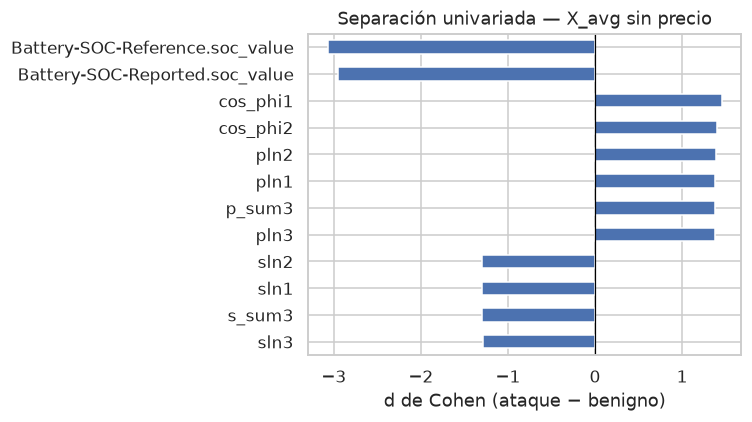

In [ ]:
def cohen_d(a, b):
    a = pd.Series(a).dropna()
    b = pd.Series(b).dropna()
    if len(a) < 5 or len(b) < 5:
        return np.nan
    sd = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sd if sd else np.nan

filas = []
for s in ["p_sum3", "i_sum3", "pln1", "sln1", "cos_phi1"]:
    crudo = f"BSS-Inverter-AC-Meter.{s}"
    if crudo in X.columns and s in X_avg.columns:
        filas.append({
            "señal": s,
            "d_medidor_BSS": cohen_d(X.loc[y == 1, crudo], X.loc[y == 0, crudo]),
            "d_promedio_5": cohen_d(X_avg.loc[y == 1, s], X_avg.loc[y == 0, s]),
        })

dilucion = pd.DataFrame(filas)
dilucion["delta_abs"] = (dilucion.d_promedio_5.abs() - dilucion.d_medidor_BSS.abs()).round(2)
display(dilucion.round(2))
print("El promedio NO atenúa parejo: en potencia y corriente del BSS reduce el efecto 33-67 %,")
print("pero en cos_phi lo amplifica porque mezcla medidores con distinto régimen. No es solo")
print("pérdida de resolución: cambia la forma del efecto y el medidor atacado deja de ser identificable.")

fuerza = pd.Series({c: cohen_d(X_avg.loc[y == 1, c], X_avg.loc[y == 0, c]) for c in X_avg.columns})
fuerza = fuerza.dropna().sort_values(key=np.abs, ascending=False)
print("\ntop 12 |d| sobre la representación promediada:")
display(fuerza.head(12).round(2).to_frame("d (ataque - benigno)"))

plt.figure(figsize=(7, 4))
fuerza.head(12).iloc[::-1].plot(kind="barh", color="#4c72b0")
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("d de Cohen (ataque − benigno)")
plt.title("Separación univariada — X_avg sin precio")
plt.tight_layout()
plt.show()

## 7. Distribuciones

Grilla sobre la matriz promediada, más el detalle del canal de precio. Se detectan constantes, bimodales y escalas absurdas, igual que en el EDA S1.

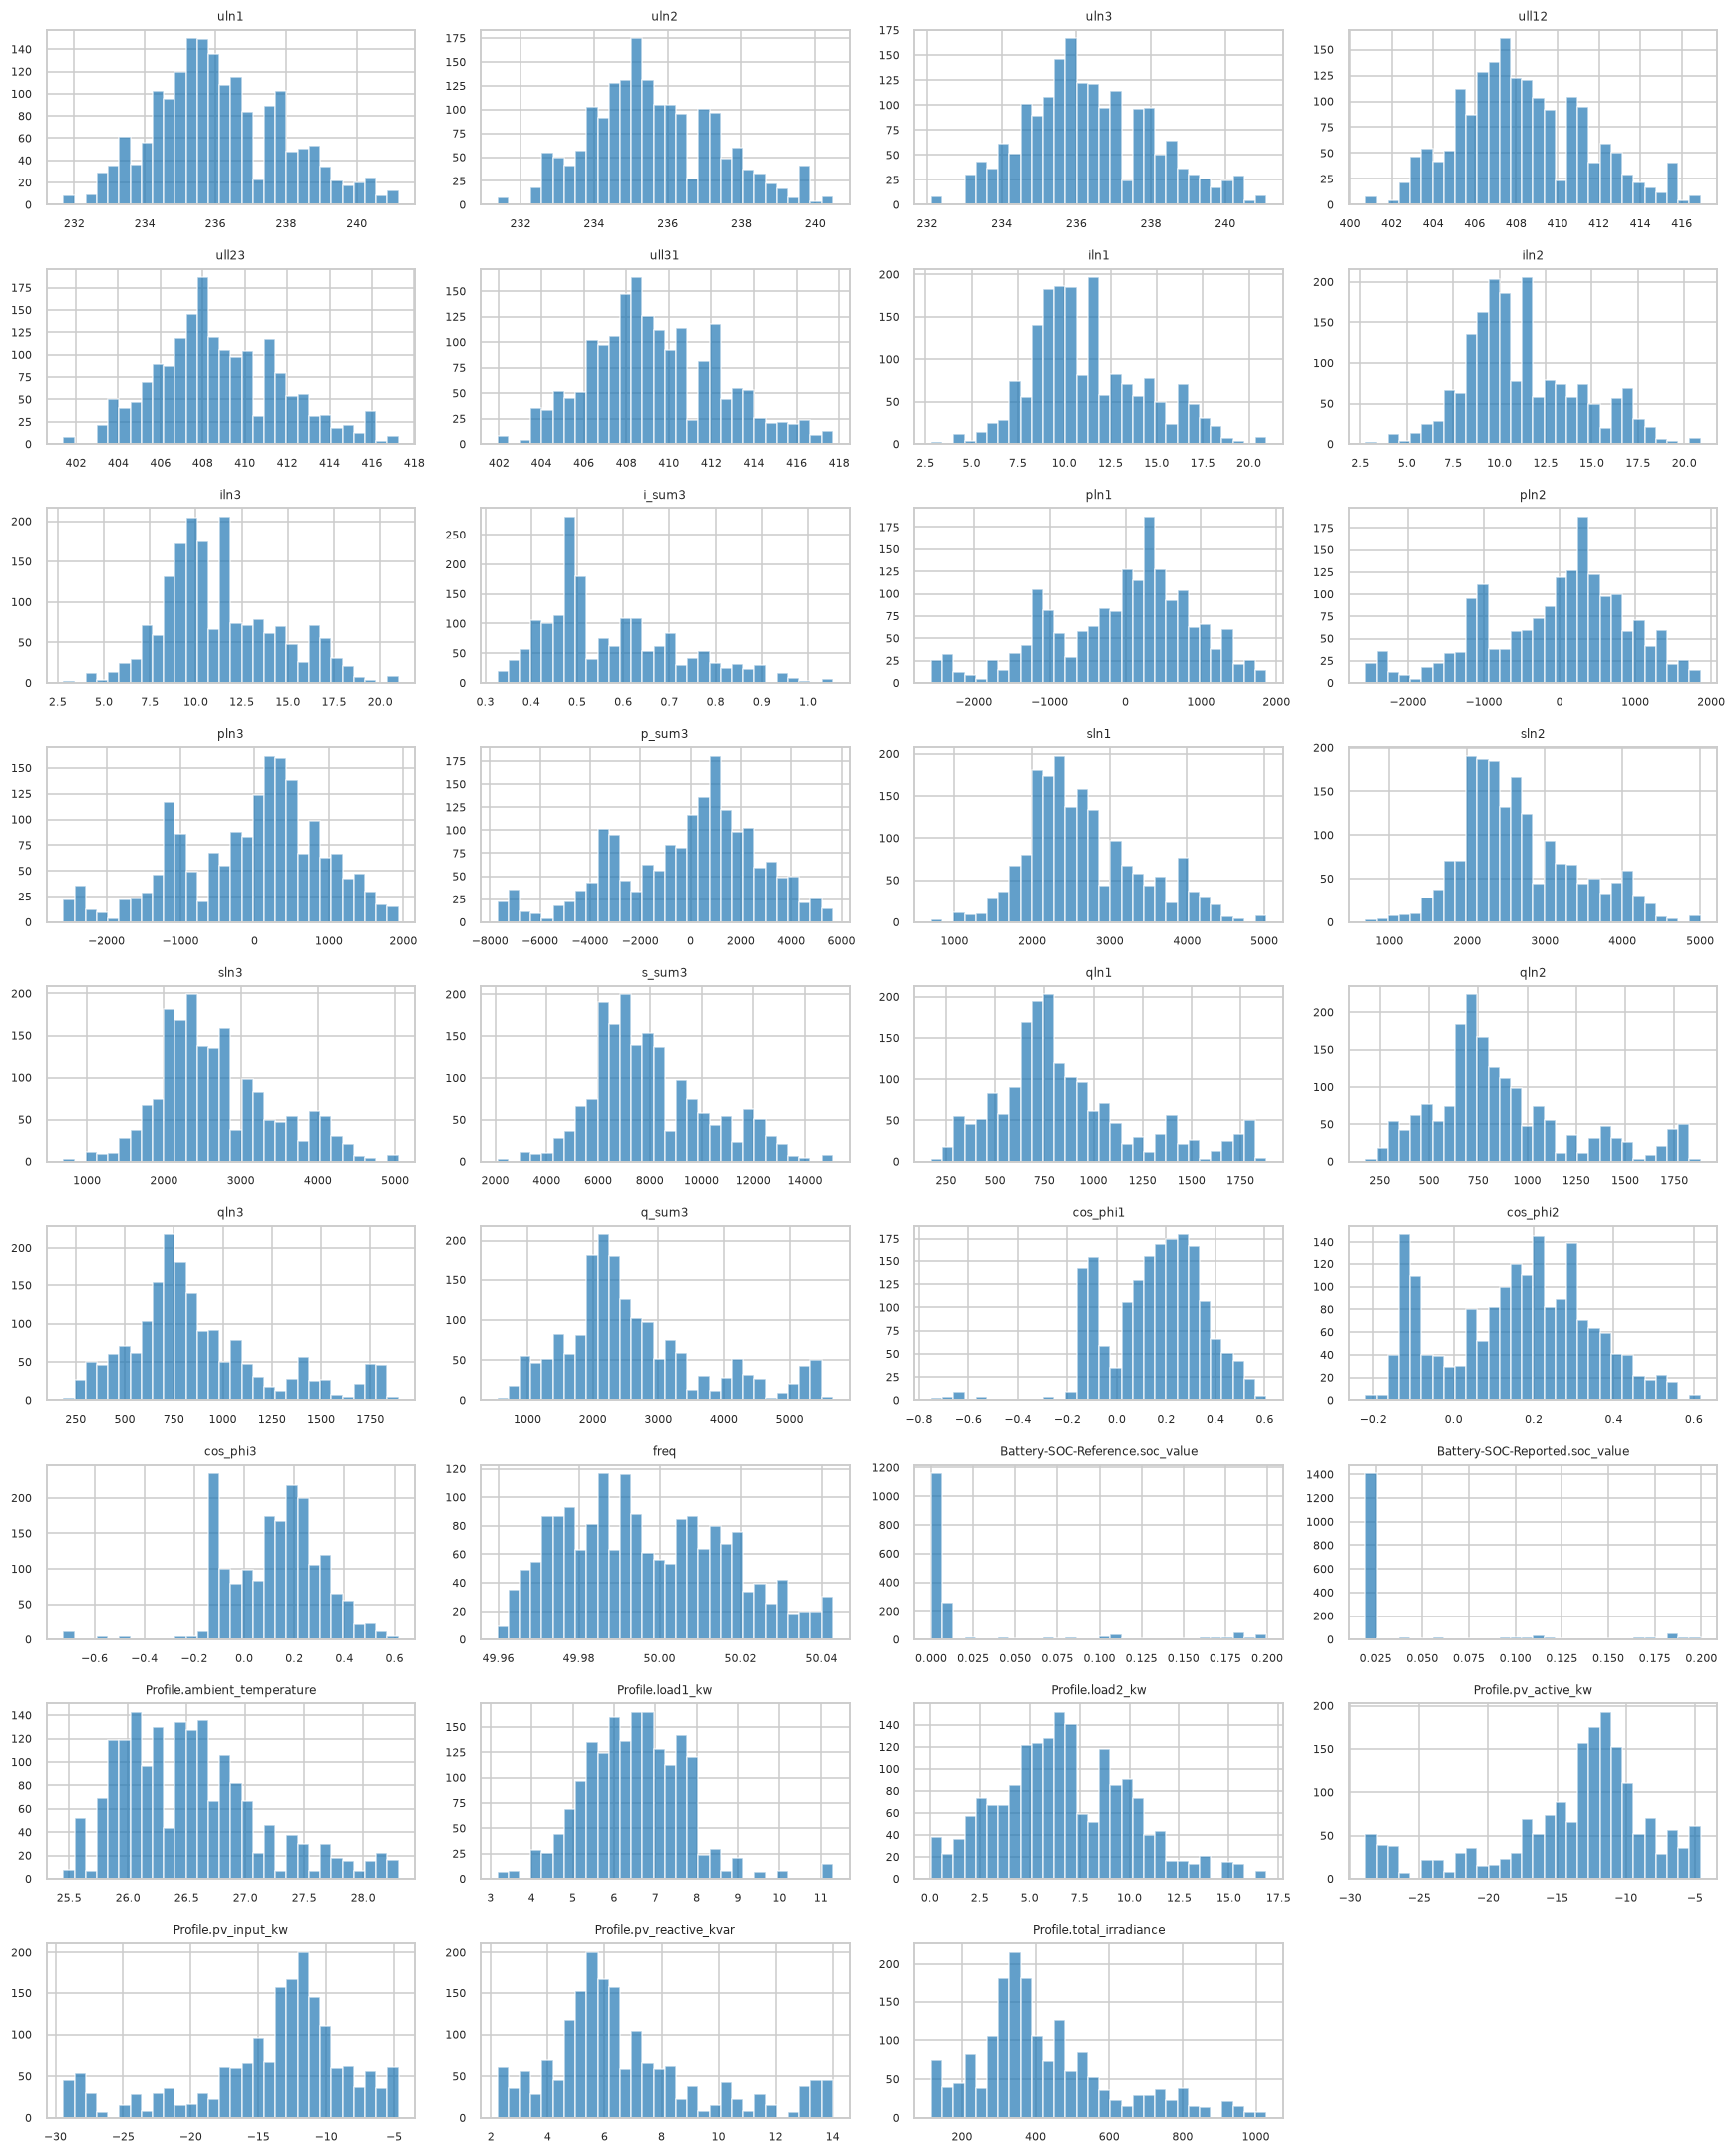

In [ ]:
columnas_plot = list(X_avg.columns)
n_cols = 4
n_rows = (len(columnas_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 2.2 * n_rows))
axes = axes.flatten()

for i, col in enumerate(columnas_plot):
    axes[i].hist(X_avg[col].dropna(), bins=30, color="tab:blue", alpha=0.7)
    axes[i].set_title(col, fontsize=8)
    axes[i].tick_params(axis="both", labelsize=7)

for j in range(len(columnas_plot), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

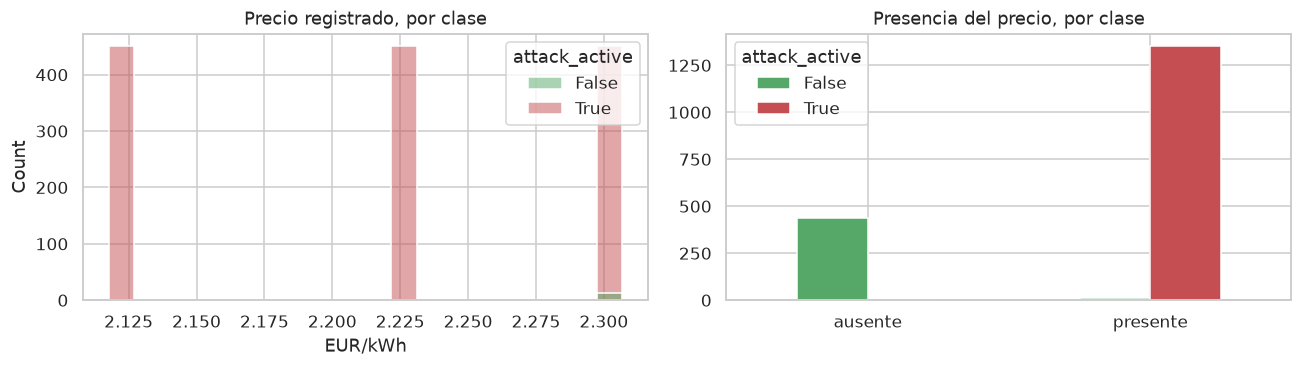

El precio toma 3 valores: dos aparecen solo en ataque y el tercero (2.3068) también en los 12 s de recuperación:
MQTT-Price-Signal.price_eur_per_kwh
2.30679    462
2.23026    450
2.11764    450
NaN        438


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

sns.histplot(data=df.dropna(subset=[PRECIO]), x=PRECIO, hue="attack_active",
             bins=20, ax=axes[0], palette={False: "#55a868", True: "#c44e52"})
axes[0].set_title("Precio registrado, por clase")
axes[0].set_xlabel("EUR/kWh")

presencia = pd.crosstab(df[PRECIO].isna().map({True: "ausente", False: "presente"}),
                        df.attack_active)
presencia.plot(kind="bar", ax=axes[1], color=["#55a868", "#c44e52"])
axes[1].set_title("Presencia del precio, por clase")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("El precio toma 3 valores: dos aparecen solo en ataque y el tercero (2.3068) también en los 12 s de recuperación:")
print(df[PRECIO].value_counts(dropna=False).to_string())

## 8. Correlación

Se agregan dos columnas de diagnóstico: `precio_ausente` e `indice_temporal`. La segunda no es una feature, es un detector de confusión: si correlaciona fuerte con el ataque, el problema es temporal.

matriz: (37, 37) | celdas indefinidas: 0


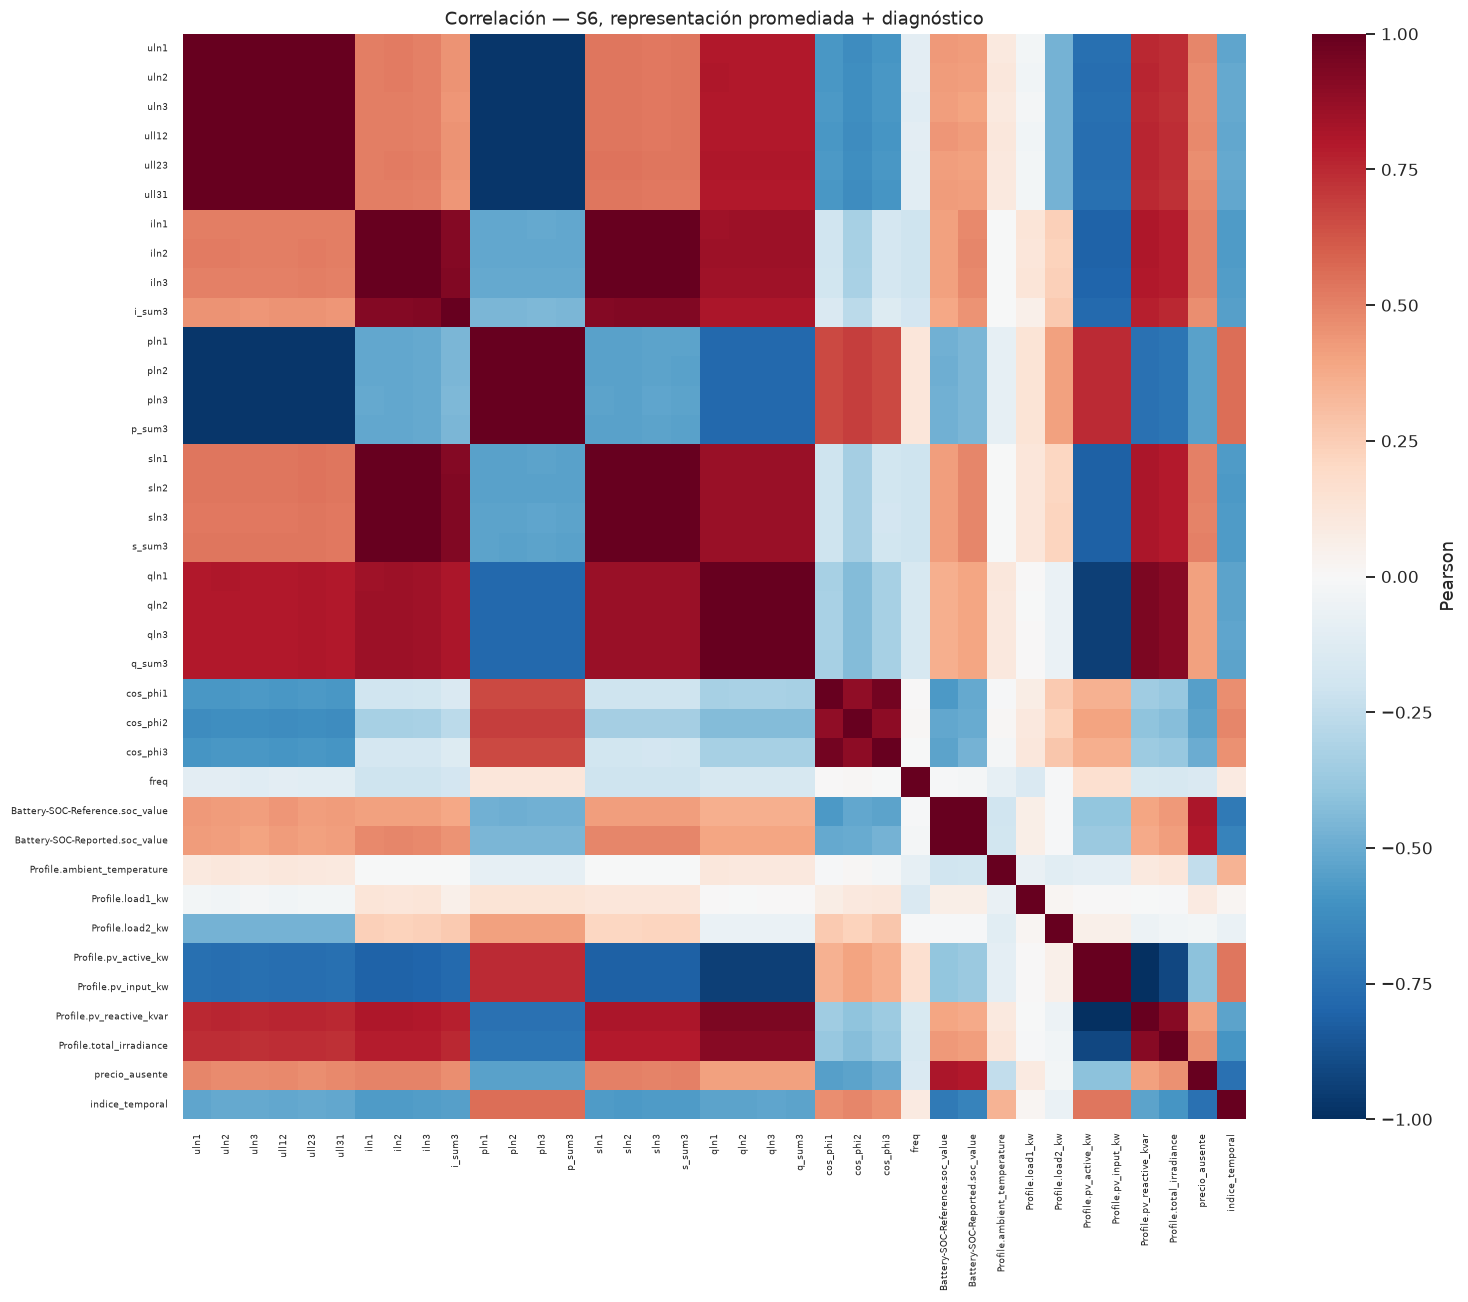

In [ ]:
diag = X_avg.copy()
diag["precio_ausente"] = df[PRECIO].isna().astype(int)
diag["indice_temporal"] = np.arange(len(df)) / len(df)

corr = diag.corr(method="pearson", min_periods=30)
print("matriz:", corr.shape, "| celdas indefinidas:", int(corr.isna().values.sum()))

plt.figure(figsize=(14, 12))
ax = sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                 linewidths=0, cbar_kws={"label": "Pearson"})
ax.set_xticklabels(ax.get_xticklabels(), fontsize=6, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=6)
plt.title("Correlación — S6, representación promediada + diagnóstico")
plt.tight_layout()
plt.show()

In [ ]:
iu = np.triu_indices_from(corr, k=1)
pares = pd.DataFrame({
    "a": corr.index[iu[0]],
    "b": corr.columns[iu[1]],
    "r": corr.values[iu],
}).dropna(subset=["r"])
pares["abs_r"] = pares.r.abs()
pares = pares.sort_values("abs_r", ascending=False).head(15).reset_index(drop=True)
display(pares.round(4))
print("\np_sum3 = pln1+pln2+pln3 y s_sum3 = sln1+sln2+sln3 por definición: colinealidad perfecta.")
print("Para RF/SVM no es fatal, pero la importancia de atributos se reparte al azar entre duplicados.")

objetivo = diag.corrwith(pd.Series(y.values, index=diag.index)).sort_values(key=np.abs, ascending=False)
print("\ncorrelación con el ataque (top 15):")
display(objetivo.head(15).round(3).to_frame("r con attack_active"))

,a,b,r,abs_r
0,Profile.pv_active_kw,Profile.pv_input_kw,1.0000,1.0000
1,sln1,s_sum3,1.0000,1.0000
2,pln3,p_sum3,1.0000,1.0000
3,sln2,s_sum3,1.0000,1.0000
4,sln3,s_sum3,0.9999,0.9999
5,pln1,pln2,0.9999,0.9999
6,sln1,sln2,0.9999,0.9999
7,iln1,iln2,0.9999,0.9999
8,iln1,iln3,0.9999,0.9999
9,sln1,sln3,0.9999,0.9999



p_sum3 = pln1+pln2+pln3 y s_sum3 = sln1+sln2+sln3 por definición: colinealidad perfecta.
Para RF/SVM no es fatal, pero la importancia de atributos se reparte al azar entre duplicados.

correlación con el ataque (top 15):


,r con attack_active
precio_ausente,-0.982
Battery-SOC-Reference.soc_value,-0.799
Battery-SOC-Reported.soc_value,-0.784
indice_temporal,0.710
cos_phi1,0.533
cos_phi2,0.517
pln2,0.515
pln1,0.514
p_sum3,0.513
pln3,0.512


In [ ]:
deriva = pd.Series({
    "indice_temporal": np.corrcoef(diag["indice_temporal"], y)[0, 1],
    "Substation.realtime": np.corrcoef(df["Substation-AC-Meter.realtime"], y)[0, 1],
    "precio_ausente": np.corrcoef(diag["precio_ausente"], y)[0, 1],
    "Battery-SOC-Reference": np.corrcoef(df["Battery-SOC-Reference.soc_value"].fillna(
        df["Battery-SOC-Reference.soc_value"].mean()), y)[0, 1],
}).sort_values(key=np.abs, ascending=False)

display(deriva.round(3).to_frame("r con el ataque"))
print("El índice temporal correlaciona fuerte: el ataque es un bloque de 22,5 minutos.")
print("Cualquier feature que derive con el tiempo (reloj, SOC, temperatura) parece predictiva sin serlo.")

,r con el ataque
precio_ausente,-0.982
Battery-SOC-Reference,-0.798
Substation.realtime,0.710
indice_temporal,0.710


El índice temporal correlaciona fuerte: el ataque es un bloque de 22,5 minutos.
Cualquier feature que derive con el tiempo (reloj, SOC, temperatura) parece predictiva sin serlo.


## 9. ACP

ACP descriptivo sobre `X_avg`, con imputación de media **solo para poder graficar** (no es la imputación del modelado). Interesa ver cuánta varianza explica la estructura y si las dos primeras componentes separan clases por física o por tiempo.

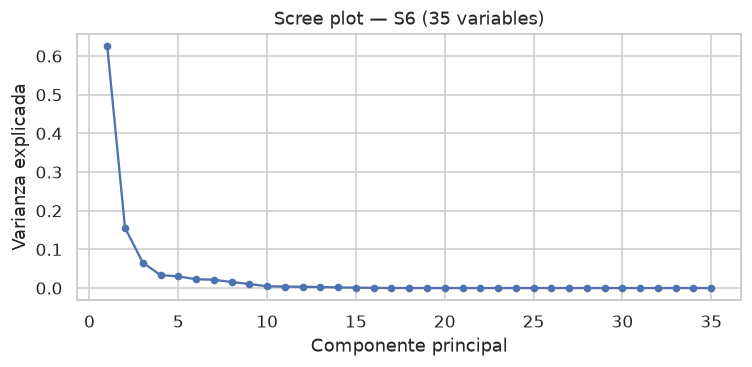

PC1 + PC2: 78.2 % de la varianza
componentes para 90 %: 5 | para 95 %: 7


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_num = X_avg.select_dtypes(include=[np.number])
X_imp = X_num.fillna(X_num.mean())
Xs = StandardScaler().fit_transform(X_imp)

pca = PCA()
Z = pca.fit_transform(Xs)

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1),
         pca.explained_variance_ratio_, marker="o", ms=4)
plt.xlabel("Componente principal")
plt.ylabel("Varianza explicada")
plt.title(f"Scree plot — {SCENARIO} ({X_imp.shape[1]} variables)")
plt.tight_layout()
plt.show()

acum = np.cumsum(pca.explained_variance_ratio_)
print(f"PC1 + PC2: {acum[1]*100:.1f} % de la varianza")
print(f"componentes para 90 %: {int(np.argmax(acum >= 0.9) + 1)} | para 95 %: {int(np.argmax(acum >= 0.95) + 1)}")

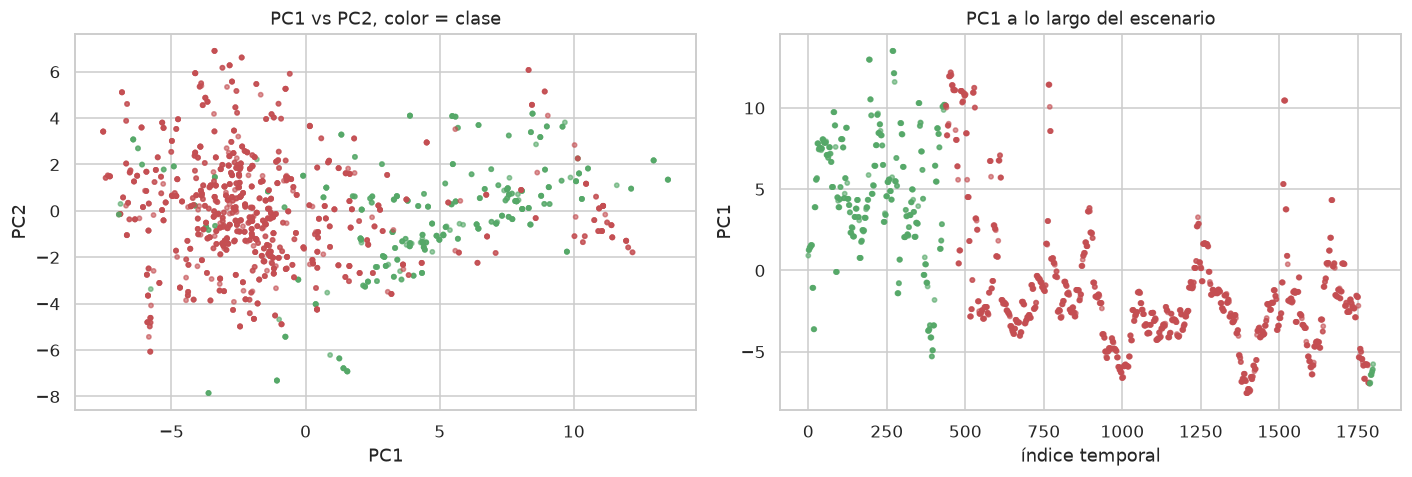

cargas de PC1 (top 10):


,carga
qln1,0.205
q_sum3,0.205
qln2,0.204
qln3,0.204
Profile.pv_input_kw,-0.196
Profile.pv_reactive_kvar,0.196
Profile.pv_active_kw,-0.196
pln2,-0.191
ull23,0.191
p_sum3,-0.191


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

colores = df.attack_active.map({False: "#55a868", True: "#c44e52"})
axes[0].scatter(Z[:, 0], Z[:, 1], c=colores, s=8, alpha=0.6)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("PC1 vs PC2, color = clase")

axes[1].scatter(np.arange(len(Z)), Z[:, 0], c=colores, s=8, alpha=0.6)
axes[1].set_xlabel("índice temporal")
axes[1].set_ylabel("PC1")
axes[1].set_title("PC1 a lo largo del escenario")

plt.tight_layout()
plt.show()

cargas = pd.Series(pca.components_[0], index=X_imp.columns).sort_values(key=np.abs, ascending=False)
print("cargas de PC1 (top 10):")
display(cargas.head(10).round(3).to_frame("carga"))

## 10. Sonda cronológica

Sin entrenar un modelo todavía: se elige **una** feature y **un** umbral usando solo el primer 60 % del escenario, y se evalúa en el 40 % final. Sirve para saber qué es razonable esperar y, sobre todo, para mostrar por qué la accuracy sola no sirve acá.

Ojo con la composición: el bloque benigno es el 24 % inicial, así que el 40 % final queda con **12 filas benignas**. La especificidad no se puede estimar con eso, y ese es justamente el punto.

In [ ]:
from sklearn.metrics import confusion_matrix

orden = df.sort_values("timestamp").index
Xc = X_fisico.loc[orden]
yc = y.loc[orden]
corte = int(len(Xc) * 0.6)

Xtr, ytr = Xc.iloc[:corte], yc.iloc[:corte]
Xte, yte = Xc.iloc[corte:], yc.iloc[corte:]

def balanced_acc(yt, yp):
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    sens = tp / max(1, tp + fn)
    spec = tn / max(1, tn + fp) if (tn + fp) else np.nan
    return ((np.nan if np.isnan(spec) else (sens + spec) / 2), sens, spec)

ranking = sorted(
    ((c, cohen_d(Xtr.loc[ytr == 1, c], Xtr.loc[ytr == 0, c])) for c in Xtr.columns),
    key=lambda t: -abs(t[1]) if pd.notna(t[1]) else 0,
)

filas = []
for c, d in ranking[:5]:
    x = Xc[c].values
    mejor = (-1, None, 1)
    for thr in np.nanpercentile(x[:corte], np.arange(5, 100, 5)):
        for signo in (1, -1):
            pred = (signo * (x - thr) > 0).astype(int)
            ba, _, _ = balanced_acc(ytr.values, pred[:corte])
            if ba > mejor[0]:
                mejor = (ba, thr, signo)
    _, thr, signo = mejor
    pred = (signo * (x - thr) > 0).astype(int)
    p_te, y_te = pred[corte:], yte.values
    tp = int(((p_te == 1) & (y_te == 1)).sum())
    fp = int(((p_te == 1) & (y_te == 0)).sum())
    fn = int(((p_te == 0) & (y_te == 1)).sum())
    tn = int(((p_te == 0) & (y_te == 0)).sum())
    filas.append({
        "feature": c,
        "d_train": round(d, 2),
        "umbral": round(float(thr), 4),
        "recall_test": round(tp / max(1, tp + fn), 3),
        "precision_test": round(tp / max(1, tp + fp), 3),
        "especificidad_test": round(tn / max(1, tn + fp), 3),
        "accuracy_test": round((tp + tn) / max(1, tp + tn + fp + fn), 3),
        "benignas_test": tn + fp,
    })

display(pd.DataFrame(filas))
print(f"test: {len(Xte)} filas | {int(yte.sum())} ataques | {int((yte == 0).sum())} benignas "
      f"({yte.mean()*100:.1f} % de ataque)")
print(f"baseline trivial (predecir ataque siempre): recall=1.000  precision={yte.mean():.3f}  "
      f"accuracy={yte.mean():.3f}  especificidad=0.000")
print("\nLectura honesta: el umbral recupera casi todo el ataque, pero las 12 filas benignas del test")
print("son los segundos de recuperación y caen todas del lado del ataque. Con 12 casos no se estima")
print("especificidad. Ese es el límite de S6, no el del modelo:")
print("un único episodio de 30 minutos sirve para construir y auditar, no para afirmar generalización.")

,feature,d_train,umbral,recall_test,precision_test,especificidad_test,accuracy_test,benignas_test
0,BSS-Inverter-AC-Meter.i_sum3,-2.98,0.1798,0.965,0.983,0.0,0.949,12
1,Battery-SOC-Reference.soc_value,-2.47,0.0166,1.000,0.983,0.0,0.983,12
2,BSS-Inverter-AC-Meter.sln2,-2.42,103.4760,0.953,0.983,0.0,0.938,12
3,BSS-Inverter-AC-Meter.iln2,-2.41,0.4817,0.952,0.983,0.0,0.936,12
4,BSS-Inverter-AC-Meter.s_sum3,-2.41,344.5032,0.959,0.983,0.0,0.943,12


test: 720 filas | 708 ataques | 12 benignas (98.3 % de ataque)
baseline trivial (predecir ataque siempre): recall=1.000  precision=0.983  accuracy=0.983  especificidad=0.000

Lectura honesta: el umbral recupera casi todo el ataque, pero las 12 filas benignas del test
son los segundos de recuperación y caen todas del lado del ataque. Con 12 casos no se estima
especificidad. Ese es el límite de S6, no el del modelo:
un único episodio de 30 minutos sirve para construir y auditar, no para afirmar generalización.


## 11. Conclusiones y decisiones

**Qué se encontró**

- S6 son 30 minutos continuos: 438 s benignos, 1350 s de ataque (75 %) y 12 s de recuperación. El ataque es un bloque temporal, no observaciones dispersas.
- `attack_phase` y `MQTT-Price-Signal.event` son etiquetas derivadas. Predicen el ataque sin física.
- El **vacío** de `price_eur_per_kwh` es otro artefacto: ausente en 438/450 benignas y en 0/1350 ataques. La regla "precio ausente → benigno" da ~99 % de accuracy sin usar una sola medición eléctrica.
- El efecto físico es real y fuerte: el inversor de batería y el SOC caen con |d| entre 2 y 3,5. Hay señal legítima.
- El promedio de los 5 medidores no atenúa parejo: en potencia y corriente del BSS baja el efecto 33-67 % (`i_sum3` pasa de |d| 3,54 a 1,18) y en `cos_phi` lo amplifica. Se conserva la señal, pero el medidor atacado deja de ser identificable.
- Hay colinealidad exacta por construcción (`p_sum3 = pln1+pln2+pln3`, `s_sum3 = sln1+sln2+sln3`, `pv_active_kw ≈ pv_input_kw`). No rompe RF/SVM, pero sí la interpretación de importancias.
- `Substation-AC-Meter.realtime` es un reloj: correlación 0,99999 con el índice de fila y 0,71 con el ataque. Es una fuga temporal clásica.
- La validación interna de S6 no puede estimar especificidad: el único bloque benigno son los primeros 438 s. Para medir falsos positivos hace falta otro escenario.

**Decisiones para el modelado**

1. Dropear `attack_phase`, `attack_phase_all`, `MQTT-Price-Signal.event`, `*.realtime` y `*.phase_seq`.
2. No usar el precio en el baseline; si se usa, agregar indicador de ausencia y reportar el contraste "con vs. sin precio". El número con precio es un control negativo, no un resultado.
3. Imputar dentro del `Pipeline`, ajustando con train. Nunca con la media global.
4. Validar cronológicamente: split temporal con separación (purga) entre train y test. El split aleatorio es inválido en S6.
5. Reportar recall, precision y especificidad por clase, más la tasa base. La accuracy sola es engañosa.
6. Tratar el desbalanceo (75/25) con `class_weight` o remuestreo, y comparar contra no hacerlo.

**Lo que este EDA todavía no responde**: si la separación se sostiene fuera de este bloque de 30 minutos. Eso solo lo responde el LOSO sobre los 8 escenarios, y por eso S6 es el punto de partida, no la conclusión.